# Food Delivery Time & Customer Satisfaction Analytics
## Mid-Sem Review-2 Prototype

**Important:** This notebook uses a controlled synthetic prototype dataset to validate the complete analytics + ML pipeline. The final project should replace/validate this dataset with the guide-approved public/collected dataset.

### Pipeline
Data → Cleaning → EDA → Statistical Analysis → Regression → Random Forest Classification → Insights → Recommendations


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, r2_score, confusion_matrix


## 1. Load the prototype dataset

In [20]:
df = pd.read_csv("food_delivery_prototype_raw.csv")
print("Raw shape:", df.shape)
display(df.head())


Raw shape: (12040, 14)


,order_id,distance_km,preparation_time_min,traffic,weather,hour,number_of_items,order_value,restaurant_rating,courier_rating,estimated_delivery_min,actual_delivery_min,customer_rating,satisfaction
0,ORD100000,5.26,17.5,Medium,Rain,11,5,671.0,3.8,4.1,60.8,72.0,3.8,Not Satisfied
1,ORD100001,3.37,17.9,Medium,Rain,19,3,346.0,3.8,4.2,60.3,72.8,NaN,Not Satisfied
2,ORD100002,3.13,24.3,Low,Clear,15,1,119.0,4.1,4.6,44.8,49.5,4.1,Satisfied
3,ORD100003,3.13,20.1,High,Clear,11,2,213.0,4.4,4.2,54.3,60.8,3.9,Not Satisfied
4,ORD100004,9.92,17.3,High,Clear,16,4,720.0,4.6,3.7,76.0,83.2,3.4,Not Satisfied


## 2. Data Quality Check
We check missing values, duplicates, data types and unusual numerical values before modeling.


In [21]:
print(df.info())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))
print("\nDuplicate order IDs:", df["order_id"].duplicated().sum())
display(df.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 12040 entries, 0 to 12039
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                12040 non-null  str    
 1   distance_km             11680 non-null  float64
 2   preparation_time_min    11800 non-null  float64
 3   traffic                 12040 non-null  str    
 4   weather                 12040 non-null  str    
 5   hour                    12040 non-null  int64  
 6   number_of_items         12040 non-null  int64  
 7   order_value             12040 non-null  float64
 8   restaurant_rating       11799 non-null  float64
 9   courier_rating          12040 non-null  float64
 10  estimated_delivery_min  12040 non-null  float64
 11  actual_delivery_min     12040 non-null  float64
 12  customer_rating         10589 non-null  float64
 13  satisfaction            12040 non-null  str    
dtypes: float64(8), int64(2), str(4)
memory usage: 1.3

customer_rating           1451
distance_km                360
restaurant_rating          241
preparation_time_min       240
order_id                     0
traffic                      0
hour                         0
weather                      0
order_value                  0
number_of_items              0
courier_rating               0
estimated_delivery_min       0
actual_delivery_min          0
satisfaction                 0
dtype: int64


Duplicate order IDs: 40


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,12040,12000,ORD100175,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
distance_km,11680.0,NaN,NaN,NaN,4.424019,2.886198,0.5,2.27,3.78,5.9225,15.0
preparation_time_min,11800.0,NaN,NaN,NaN,19.985669,5.432918,8.0,16.1,20.0,23.7,40.5
traffic,12040,3,Medium,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather,12040,3,Clear,6612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour,12040.0,NaN,NaN,NaN,15.986047,3.758974,10.0,13.0,16.0,19.0,22.0
number_of_items,12040.0,NaN,NaN,NaN,2.324169,1.189488,1.0,1.0,2.0,3.0,5.0
order_value,12040.0,NaN,NaN,NaN,328.843605,213.474126,80.0,166.0,289.0,437.0,5256.0
restaurant_rating,11799.0,NaN,NaN,NaN,4.094339,0.445657,2.5,3.8,4.1,4.4,5.0
courier_rating,12040.0,NaN,NaN,NaN,4.189759,0.393473,2.8,3.9,4.2,4.5,5.0


## 3. Data Cleaning
- Remove duplicate order IDs
- Fill numerical missing values with the median
- Cap extreme outliers using the IQR rule
- Recreate the satisfaction label from customer rating


In [22]:
clean = df.drop_duplicates(subset=["order_id"]).copy()
num_cols = ["distance_km","preparation_time_min","restaurant_rating","courier_rating",
            "estimated_delivery_min","actual_delivery_min","order_value","number_of_items","hour"]
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())

for c in ["order_value","actual_delivery_min"]:
    q1, q3 = clean[c].quantile([.25,.75])
    iqr = q3-q1
    clean[c] = clean[c].clip(q1-1.5*iqr, q3+1.5*iqr)

clean["satisfaction"] = np.where(clean["customer_rating"]>=4, "Satisfied", "Not Satisfied")
print("Cleaned shape:", clean.shape)


Cleaned shape: (12000, 14)


## 4. Exploratory Data Analysis

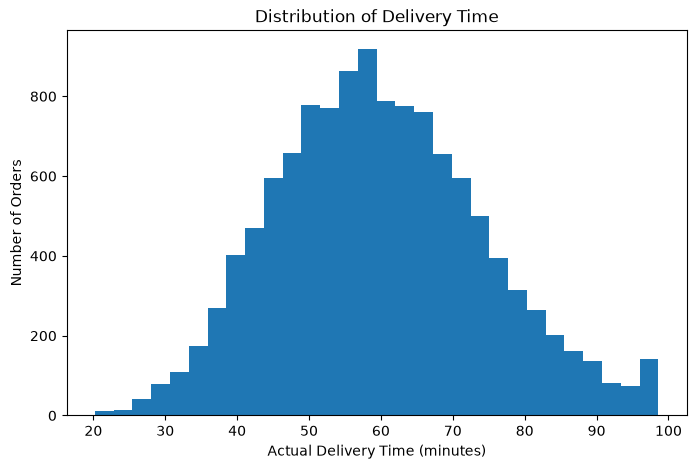

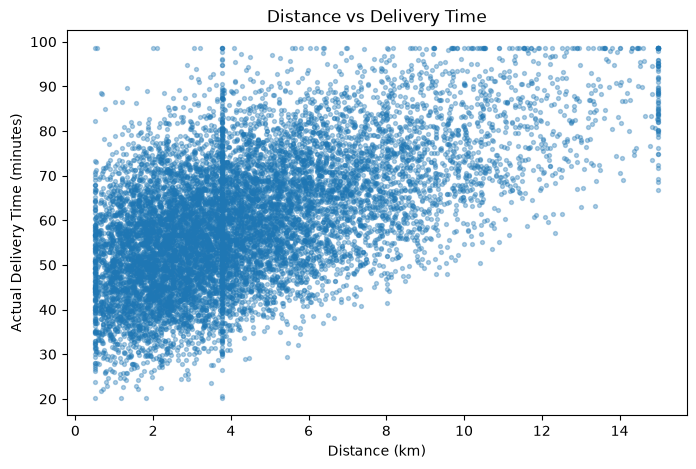

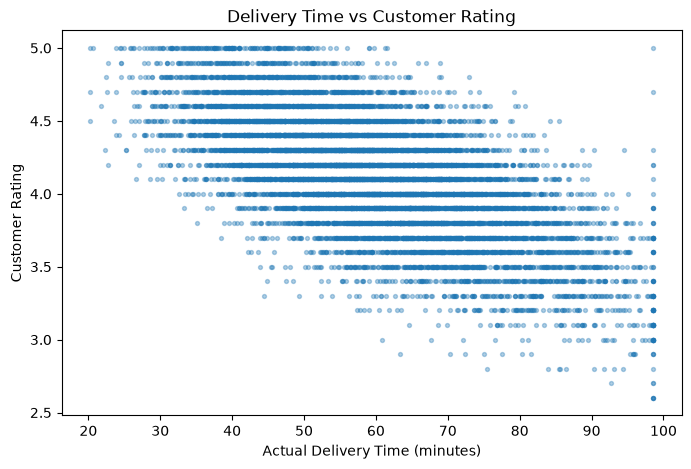

In [23]:
plt.figure(figsize=(8,5))
plt.hist(clean["actual_delivery_min"], bins=30)
plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Delivery Time")
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(clean["distance_km"], clean["actual_delivery_min"], s=8, alpha=.35)
plt.xlabel("Distance (km)")
plt.ylabel("Actual Delivery Time (minutes)")
plt.title("Distance vs Delivery Time")
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(clean["actual_delivery_min"], clean["customer_rating"], s=8, alpha=.35)
plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Customer Rating")
plt.title("Delivery Time vs Customer Rating")
plt.show()


## 5. Statistical Analysis

In [24]:
analysis = clean.dropna(subset=["customer_rating"]).copy()
print("Mean delivery time:", round(analysis["actual_delivery_min"].mean(),2))
print("Median delivery time:", round(analysis["actual_delivery_min"].median(),2))
print("Std. deviation:", round(analysis["actual_delivery_min"].std(),2))
print("Mean customer rating:", round(analysis["customer_rating"].mean(),2))
print("Delivery-time / rating correlation:",
      round(analysis["actual_delivery_min"].corr(analysis["customer_rating"]),3))

analysis["delivery_band"] = pd.cut(
    analysis["actual_delivery_min"],
    bins=[0,30,45,60,999],
    labels=["≤30 min","31–45 min","46–60 min",">60 min"]
)
display(analysis.groupby("delivery_band", observed=False)["customer_rating"].agg(["count","mean"]))


Mean delivery time: 59.91
Median delivery time: 59.1
Std. deviation: 14.42
Mean customer rating: 4.12
Delivery-time / rating correlation: -0.672


,count,mean
delivery_band,,
≤30 min,101,4.654455
31–45 min,1547,4.494699
46–60 min,3911,4.248888
>60 min,5001,3.884263


## 6. Multiple Linear Regression — Delivery Time

In [25]:
features_reg = ["distance_km","preparation_time_min","number_of_items",
                "restaurant_rating","courier_rating","estimated_delivery_min","hour"]
X = clean[features_reg]
y = clean["actual_delivery_min"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.2,random_state=42)

model = LinearRegression()
model.fit(X_train,y_train)
pred = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test,pred),2), "minutes")
print("R²:", round(r2_score(y_test,pred),3))


MAE: 3.32 minutes
R²: 0.903


## 7. Random Forest Classification — Customer Satisfaction

Target:
- **Satisfied:** rating ≥ 4
- **Not Satisfied:** rating < 4

The model uses variables that can be available before/around delivery, such as estimated delivery time, distance, preparation time, traffic, weather and ratings.


In [26]:
features = ["distance_km","preparation_time_min","traffic","weather","hour",
            "number_of_items","order_value","restaurant_rating",
            "courier_rating","estimated_delivery_min"]
X = clean[features]
y = clean["satisfaction"]

num = ["distance_km","preparation_time_min","hour","number_of_items","order_value",
       "restaurant_rating","courier_rating","estimated_delivery_min"]
cat = ["traffic","weather"]

pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)
])

rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, min_samples_leaf=3,
    class_weight="balanced", random_state=42
)

pipe = Pipeline([("prep",pre),("model",rf)])
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=.2,random_state=42,stratify=y
)
pipe.fit(X_train,y_train)
pred = pipe.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test,pred),3))
print("F1 (Satisfied):", round(f1_score(y_test,pred,pos_label="Satisfied"),3))
print("Confusion matrix:")
print(confusion_matrix(y_test,pred,labels=["Not Satisfied","Satisfied"]))


Accuracy: 0.724
F1 (Satisfied): 0.767
Confusion matrix:
[[ 648  346]
 [ 316 1090]]


## 8. Feature Importance

,feature,importance
7,num__estimated_delivery_min,0.315666
5,num__restaurant_rating,0.137601
0,num__distance_km,0.135147
1,num__preparation_time_min,0.073826
13,cat__weather_Rain,0.068898
6,num__courier_rating,0.068020
4,num__order_value,0.058319
2,num__hour,0.037029
8,cat__traffic_High,0.029696
9,cat__traffic_Low,0.021439


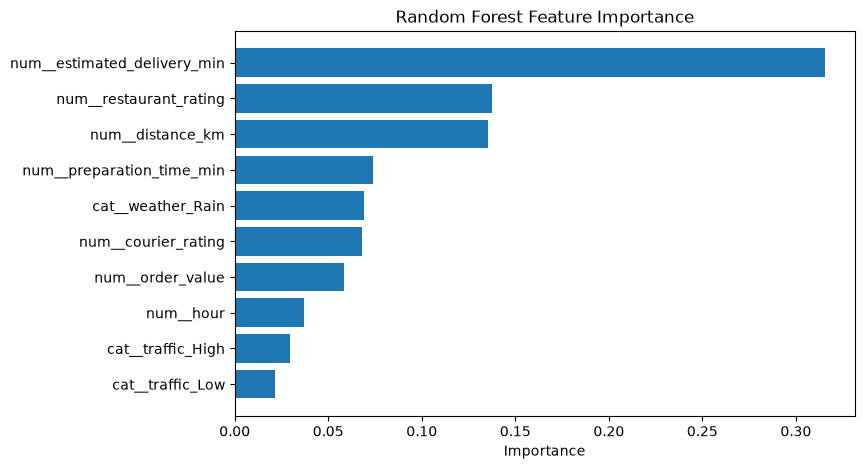

In [27]:
names = pipe.named_steps["prep"].get_feature_names_out()
importance = pd.DataFrame({
    "feature": names,
    "importance": pipe.named_steps["model"].feature_importances_
}).sort_values("importance",ascending=False)
display(importance.head(10))

plt.figure(figsize=(8,5))
top = importance.head(10).iloc[::-1]
plt.barh(top["feature"],top["importance"])
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.show()


## 9. Preliminary Insights
The prototype analysis should be treated as a validation of the methodology, not as final real-world findings.

Expected final insights will focus on:
1. Which variables are most strongly associated with delivery time.
2. Whether longer delivery times are associated with lower customer ratings.
3. Which features contribute most to satisfaction prediction.
4. Which orders should be flagged as potential satisfaction-risk cases.
5. What operational actions could improve customer experience.


## 10. Next Steps
- Finalize the guide-approved real/public dataset.
- Repeat cleaning and EDA on the final dataset.
- Compare Linear Regression with Random Forest for delivery-time prediction.
- Tune and validate the Random Forest satisfaction model.
- Add a simple dashboard/prototype for prediction and recommendations.
- Document limitations and final business recommendations.
